# FM 주파수 변조 실습
**실행 환경:** Google Colab · Python

이 교재는 통신 개념뿐 아니라, 코드가 왜 그런 문법으로 작성되는지도 설명합니다. 각 코드 셀에는 핵심 문법을 주석으로 적었습니다. 처음에는 코드를 그대로 실행하고, 다음에는 설명에 나온 숫자를 직접 바꿔 보세요.

## 이 실습에서 배울 것
1. 파이썬에서 변수에 값을 저장하는 방법
2. `import`, `np.arange()`, `np.cos()`가 하는 일
3. 배열을 이용해 시간에 따른 신호를 만드는 원리
4. FM 변조지수와 FM 파형의 관계
5. AM과 FM의 파형 차이
6. FFT 스펙트럼과 간단한 FM 복조

## 1. 먼저 파이썬 문법부터 보기

### 변수와 `=`
`fm = 100`은 “fm이라는 이름의 변수에 숫자 100을 저장하라”는 뜻입니다. 수학의 등호처럼 양쪽이 같다는 뜻이 아니라, 파이썬에서는 **대입**을 뜻합니다.

### `import`
`import numpy as np`는 계산용 라이브러리 NumPy를 불러오고, 이후 `np`라는 짧은 이름으로 사용하겠다는 뜻입니다.

### 함수 호출의 괄호 `()`
`np.cos(값)`은 괄호 안의 값을 코사인 함수에 전달해 계산하라는 뜻입니다. 함수에 전달하는 값을 **인자(argument)**라고 합니다.

### `#` 주석
`#` 뒤의 내용은 파이썬이 실행하지 않습니다. 사람이 코드를 이해하도록 적는 설명입니다.

In [1]:
# import는 다른 사람이 만들어 둔 계산 기능을 불러오는 문법입니다.
import numpy as np               # NumPy를 np라는 짧은 이름으로 사용
import matplotlib.pyplot as plt  # 그래프 그리기 도구를 plt로 사용

# 변수는 값을 저장하는 이름입니다. 여기서는 신호 계산에 필요한 숫자를 저장합니다.
fs = 100_000       # 표본화 주파수: 1초에 100,000번 계산
duration = 0.03    # 신호를 관찰할 시간: 0.03초
fm = 100           # 메시지 신호 주파수: 100 Hz

# np.arange(시작, 끝, 간격)은 시작부터 끝 직전까지 일정한 간격의 숫자 배열을 만듭니다.
# 1/fs는 표본 사이의 시간 간격입니다. fs가 클수록 시간 간격은 짧아집니다.
t = np.arange(0, duration, 1/fs)

# np.cos()는 코사인 값을 계산합니다.
# 2*pi*fm*t는 시간 t마다 코사인 함수에 넣을 각도를 배열로 계산합니다.
message = np.cos(2 * np.pi * fm * t)

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54253 (\N{HANGUL SYLLABLE POG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47700 (\N{HANGUL SYLLABLE ME}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/loc

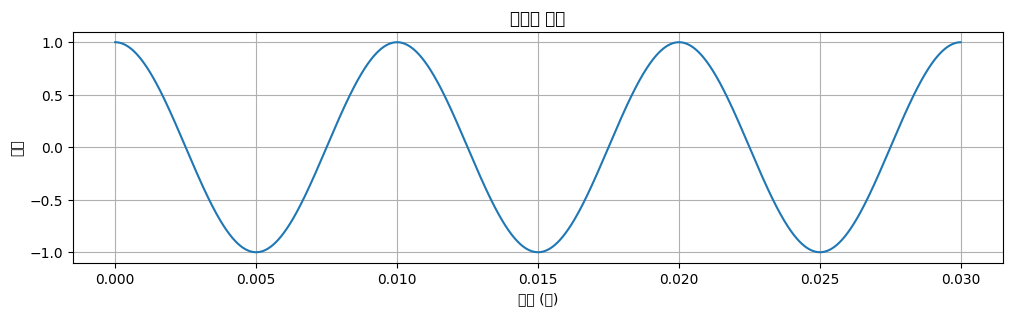

표본 수: 3000
시간 간격(초): 1e-05


In [2]:
# plt.figure()는 그래프 창을 만들고, figsize는 그래프 크기를 지정합니다.
plt.figure(figsize=(12, 3))
plt.plot(t, message)             # x축에 시간 t, y축에 신호값 message를 그립니다.
plt.title("메시지 신호")          # 그래프 제목
plt.xlabel("시간 (초)")           # 가로축 이름
plt.ylabel("진폭")                # 세로축 이름
plt.grid(True)                   # 격자 표시
plt.show()                       # 그래프를 실제로 출력

print("표본 수:", len(t))         # len()은 배열에 들어 있는 값의 개수를 알려줍니다.
print("시간 간격(초):", 1/fs)     # 계산한 시간 간격 출력(1e-04 = 0.0001)

### 실행 결과를 이해하기
- `t`에는 `0`, `0.00001`, `0.00002`처럼 시간값이 많이 들어 있습니다.
- `message`에는 각 시간에서 계산한 코사인값이 들어 있습니다.
- `plt.plot(t, message)`는 같은 위치에 있는 시간값과 신호값을 짝지어 선 그래프로 그립니다.
- `len(t)`는 시간값이 몇 개 생성되었는지 알려줍니다.

**직접 바꾸기:** `fm = 100`을 `fm = 200`으로 바꾸세요. 주파수가 두 배가 되면 같은 시간 안에 진동이 두 배 가까이 나타납니다.

## 2. FM 변조식과 파이썬 코드 연결하기

FM은 메시지 신호에 따라 반송파의 **순간 주파수**를 변화시키는 방식입니다. 이 실습에서는 다음 식을 사용합니다.

\[
s(t)=A_c\cos\left(2\pi f_ct+\beta\sin(2\pi f_mt)\right)
\]

- `Ac`: 반송파 진폭
- `fc`: 반송파 주파수
- `fm`: 메시지 주파수
- `delta_f`: 최대 주파수 편이
- `beta = delta_f / fm`: 변조지수

파이썬에서는 곱셈을 `*`, 나눗셈을 `/`로 씁니다. 괄호는 계산 순서를 명확하게 보여 줍니다.

/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 47700 (\N{HANGUL SYLLABLE ME}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 49888 (\N{HANGUL SYLLABLE SIN}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 54840 (\N{HANGUL SYLLABLE HO}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missin

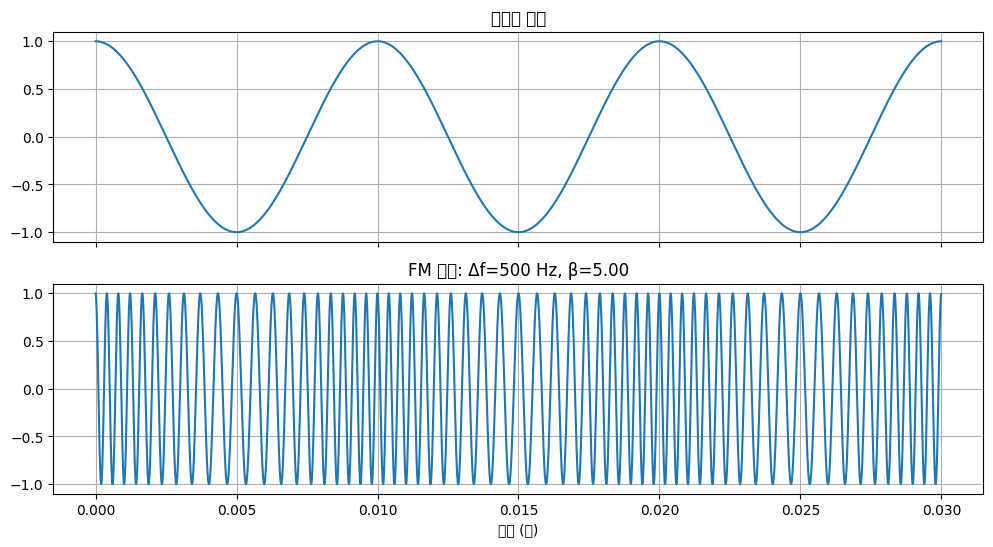

In [3]:
# 실험에 사용할 숫자들을 변수로 지정합니다. 값을 바꾸면 아래 계산 결과도 달라집니다.
fc = 2_000       # 반송파 주파수 2,000 Hz
delta_f = 500    # 최대 주파수 편이 500 Hz
Ac = 1.0         # 반송파 진폭

# FM 변조지수는 최대 편이를 메시지 주파수로 나눈 값입니다.
beta = delta_f / fm

# 앞의 셀에서 구한 message 값을 그대로 가져와 누적 합산(적분)합니다.
# (이 셀에서는 message = np.cos(...) 줄을 삭제해야 앞의 값이 유지됩니다)
dt = 1 / fs
integral_message = np.cumsum(message) * dt

# ★ 중요: 수식의 위상 변화 부분에 진짜 integral_message를 대입하여 수정합니다.
# 수학적 정의에 따라 2 * np.pi * delta_f와 누적 합산된 신호를 곱해줍니다.
fm_signal = Ac * np.cos(
    2 * np.pi * fc * t + 2 * np.pi * delta_f * integral_message
)

# 두 개의 그래프 영역을 위아래로 만듭니다.
# subplots(2, 1)은 2행 1열이라는 뜻이고, sharex=True는 시간축을 공유합니다.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax[0].plot(t, message)           # 첫 번째 영역 ax[0]에 메시지 신호를 그림
ax[0].set_title("메시지 신호")
ax[0].grid(True)

ax[1].plot(t, fm_signal)         # 두 번째 영역 ax[1]에 FM 신호를 그림
ax[1].set_title(f"FM 신호: Δf={delta_f} Hz, β={beta:.2f}")
# f"문자열 {변수}"는 변수값을 문장 안에 넣는 f-string 문법입니다.
# :.2f는 소수점 아래 두 자리까지 표시하라는 형식 지정입니다.
ax[1].set_xlabel("시간 (초)")
ax[1].grid(True)

In [4]:
plt.tight_layout()               # 그래프와 글자가 겹치지 않도록 간격 조정
plt.show()                       # 꼭 붙여주는 습관을 기르자.
print("FM 변조지수 beta =", beta)

<Figure size 640x480 with 0 Axes>

FM 변조지수 beta = 5.0


### 코드의 핵심 문법
- `beta = delta_f / fm`: 오른쪽 계산 결과를 `beta` 변수에 저장합니다.
- `fm_signal = ...`: 수식의 계산 결과 배열 전체를 변수에 저장합니다.
- `ax[0]`, `ax[1]`: 그래프 영역을 순서 번호로 선택합니다. 파이썬의 번호는 보통 0부터 시작합니다.
- `f"FM 신호: {delta_f}"`: 중괄호 안의 변수값을 문자열에 삽입합니다.

**실험:** `delta_f`를 `150`, `500`, `1000`으로 바꾸어 실행하세요. `beta` 값과 파형이 어떻게 달라지는지 확인합니다.

## 3. AM과 FM 비교하기

AM은 메시지에 따라 반송파의 진폭을 바꿉니다. FM은 메시지에 따라 반송파의 순간 주파수를 바꿉니다.

AM의 간단한 식은 다음과 같습니다.

\[
s_{AM}(t)=A_c[1+\mu m(t)]\cos(2\pi f_ct)
\]

여기서 `mu`는 AM 변조도입니다. 이번 비교는 원리를 보여주기 위한 단순한 예제입니다.

/tmp/ipykernel_1629/2990804912.py:17: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/2990804912.py:17: UserWarning: Glyph 54253 (\N{HANGUL SYLLABLE POG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/2990804912.py:17: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/2990804912.py:17: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/2990804912.py:17: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/2990804912.py:17: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/2990804912.py:17: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_la

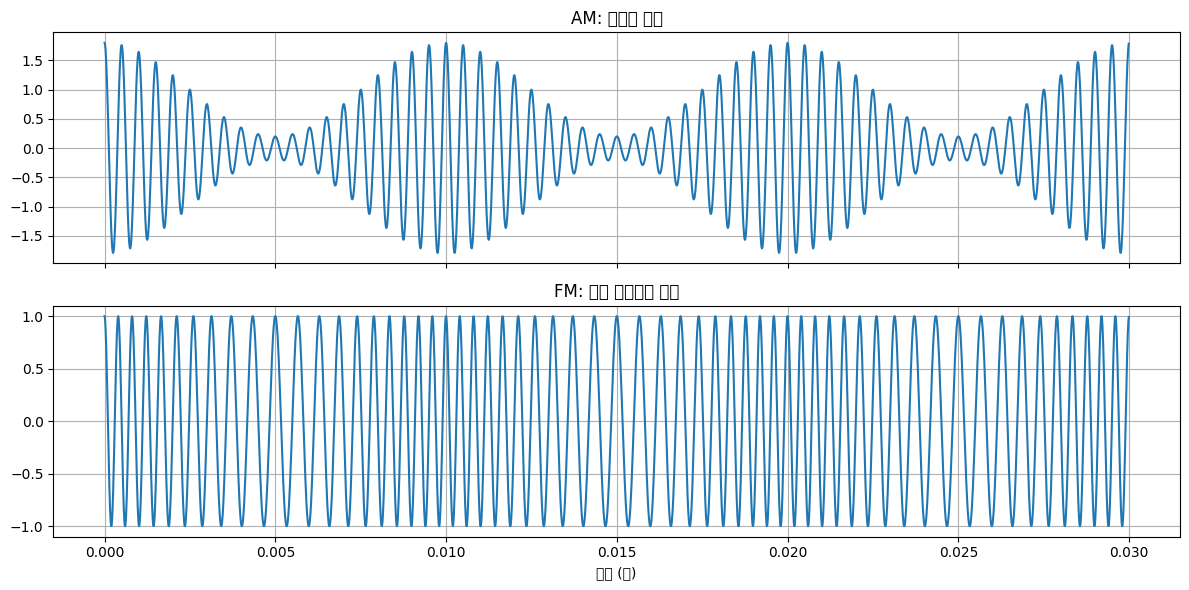

In [5]:
mu = 0.8  # AM 변조도. 0.8은 메시지에 따라 진폭이 크게 변하도록 한 설정입니다.

# AM: (1 + mu*message)가 반송파의 진폭을 조절하는 포락선 역할을 합니다.
am_signal = (1 + mu * message) * np.cos(2 * np.pi * fc * t)

# 같은 시간축에서 AM과 FM을 위아래로 비교합니다.
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(t, am_signal)
ax[0].set_title("AM: 진폭이 변함")
ax[0].grid(True)

ax[1].plot(t, fm_signal)
ax[1].set_title("FM: 순간 주파수가 변함")
ax[1].set_xlabel("시간 (초)")
ax[1].grid(True)

plt.tight_layout()
plt.show()

### 그래프를 읽는 방법
AM 파형은 바깥쪽 윤곽(진폭)이 메시지 모양에 따라 커졌다 작아집니다. FM 파형은 진폭이 대체로 일정하지만 파형의 주기가 촘촘해졌다 느슨해집니다.

**직접 해보기:** `mu = 0.2`와 `mu = 0.9`를 각각 실행해 AM 진폭 변화의 크기를 비교하세요.

## 4. 주파수 스펙트럼(FFT) 보기

시간 그래프는 신호가 시간에 따라 어떻게 변하는지 보여줍니다. 주파수 스펙트럼은 신호에 어떤 주파수 성분이 포함되어 있는지 보여줍니다.

`np.fft.rfft()`는 실수 신호의 FFT를 계산하고, `np.fft.rfftfreq()`는 각 결과가 어느 주파수에 해당하는지 계산합니다.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53356 (\N{HANGUL SYLLABLE KEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

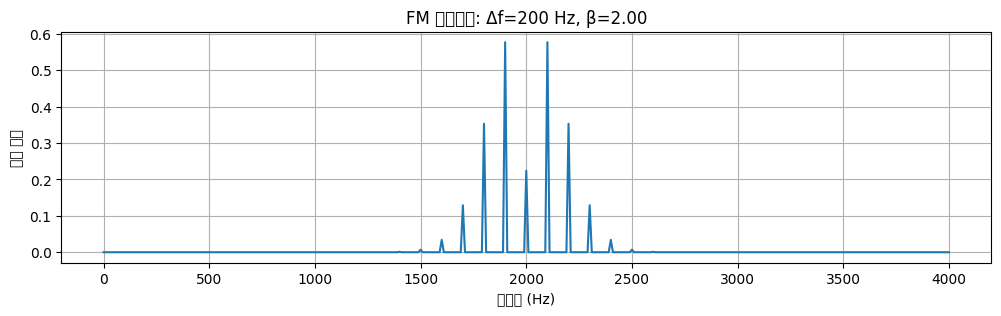

카슨 법칙 대역폭 근사: 600 Hz


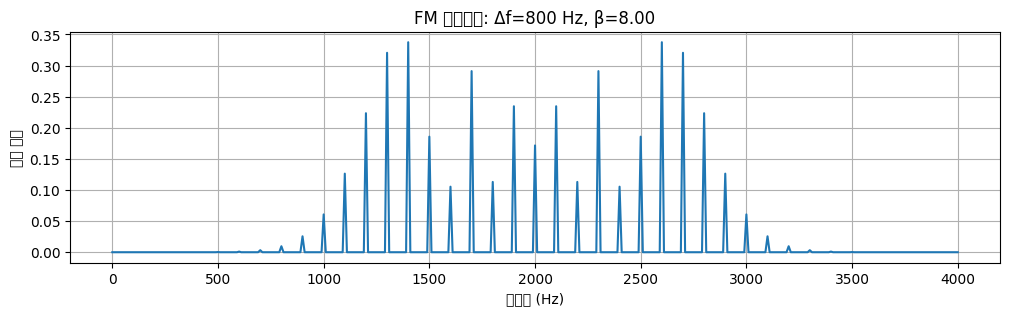

카슨 법칙 대역폭 근사: 1800 Hz


In [6]:
def fm_spectrum(delta_f, fc=2000, fm=100, fs=100000, duration=0.1):
    # def는 함수를 정의하는 문법입니다.
    # 괄호 안의 값은 함수에 전달하는 입력값이며, =가 있는 값은 기본값입니다.
    tt = np.arange(0, duration, 1/fs)
    beta = delta_f / fm
    x = np.cos(2*np.pi*fc*tt + beta*np.sin(2*np.pi*fm*tt))

    X = np.fft.rfft(x)             # 신호를 주파수 영역으로 변환
    freq = np.fft.rfftfreq(len(x), 1/fs)  # FFT 각 점의 주파수값
    magnitude = 2*np.abs(X)/len(x) # abs는 크기, len은 표본 개수

    # 조건을 만족하는 주파수만 골라 표시합니다.
    # &는 두 조건을 동시에 만족해야 한다는 뜻입니다.
    mask = (freq >= fc-2000) & (freq <= fc+2000)

    plt.figure(figsize=(12, 3))
    plt.plot(freq[mask], magnitude[mask])  # mask가 True인 데이터만 그래프에 표시
    plt.title(f"FM 스펙트럼: Δf={delta_f} Hz, β={beta:.2f}")
    plt.xlabel("주파수 (Hz)")
    plt.ylabel("상대 크기")
    plt.grid(True)
    plt.show()

    # 함수가 계산한 결과를 사람이 읽을 수 있게 출력합니다.
    print("카슨 법칙 대역폭 근사:", 2*(delta_f + fm), "Hz")

# 함수를 호출할 때 괄호 안에 실험값을 넣습니다.
fm_spectrum(200)
fm_spectrum(800)

### 함수 문법을 이해하기
- `def fm_spectrum(...):`는 반복해서 쓸 작업을 함수로 묶어 이름을 붙입니다.
- 함수 안의 코드는 들여쓰기를 해야 합니다. 들여쓰기는 “이 코드가 함수에 속한다”는 뜻입니다.
- `fm_spectrum(200)`은 함수에 `delta_f=200`을 전달해 실행합니다.
- 같은 코드를 복사해 두 번 쓰는 대신, 입력값만 바꿔 같은 작업을 수행할 수 있습니다.

**관찰:** 편이 200 Hz와 800 Hz의 스펙트럼 폭을 비교하세요. 교육용 근사식인 카슨 법칙은 `B ≈ 2(Δf + fm)`입니다.

## 5. FM 복조: 위상 변화에서 주파수 찾기

FM 신호의 위상 변화를 측정하면 순간 주파수를 추정할 수 있습니다. 아래 예제는 교육용으로 `hilbert()`를 이용해 위상을 구한 뒤, 연속 표본 간 위상 차이로 주파수를 계산합니다. 실제 FM 수신기의 모든 회로를 구현한 것은 아닙니다.

/tmp/ipykernel_1629/1298188882.py:33: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/1298188882.py:33: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/1298188882.py:33: UserWarning: Glyph 47700 (\N{HANGUL SYLLABLE ME}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/1298188882.py:33: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/1298188882.py:33: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/1298188882.py:33: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1629/1298188882.py:33: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  plt.tight_layo

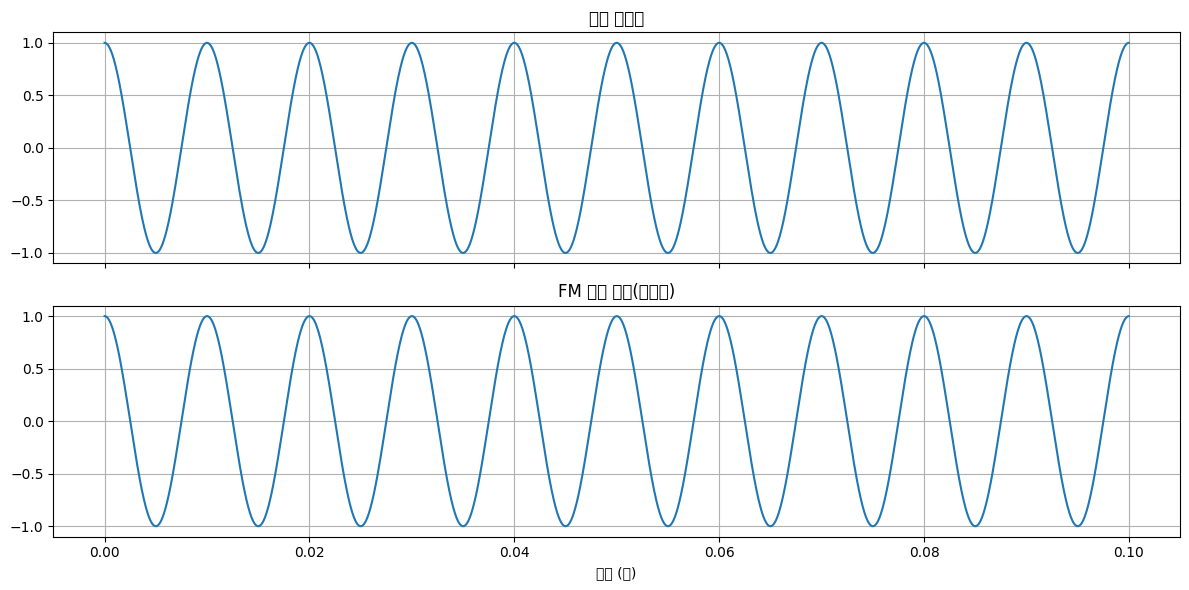

In [7]:
from scipy.signal import hilbert  # 신호 분석에 필요한 Hilbert 변환 기능을 불러옵니다.

fs = 100_000
t = np.arange(0, 0.1, 1/fs)
fm = 100
fc = 2_000
delta_f = 500

message = np.cos(2*np.pi*fm*t)
x = np.cos(2*np.pi*fc*t + (delta_f/fm)*np.sin(2*np.pi*fm*t))

analytic = hilbert(x)             # 실수 신호에서 위상 분석에 쓸 복조 신호 생성
phase = np.unwrap(np.angle(analytic))
# np.angle는 위상각을 구하고, np.unwrap은 각도가 갑자기 튀는 현상을 이어 줍니다.

inst_freq = np.diff(phase) * fs / (2*np.pi)
# np.diff는 이웃한 표본 사이의 차이를 구합니다.
# 위상 변화량에 fs를 곱해 초당 변화량으로 바꾸면 순간 주파수를 추정할 수 있습니다.

demod = inst_freq - fc            # 기준 반송파 주파수를 빼 메시지에 비례하는 성분을 얻음
demod = (demod - np.mean(demod)) / delta_f
# np.mean은 평균입니다. 평균을 빼고 delta_f로 나누어 비교하기 편하게 정규화합니다.

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(t, message)
ax[0].set_title("원래 메시지")
ax[0].grid(True)
ax[1].plot(t[1:], demod)
# np.diff 결과는 원래 배열보다 한 항목 짧으므로 시간축도 t[1:]로 맞춥니다.
ax[1].set_title("FM 복조 결과(정규화)")
ax[1].set_xlabel("시간 (초)")
ax[1].grid(True)
plt.tight_layout()
plt.show()

## 6. 잡음이 FM 복조에 미치는 영향

통신 채널에 잡음이 섞이면 복조 결과도 달라질 수 있습니다. 아래 함수는 잡음의 표준편차를 입력받아 FM 신호에 잡음을 더하고 복조 결과를 돌려줍니다.

`np.random.normal(평균, 표준편차, 크기)`는 정규분포를 따르는 임의의 잡음 배열을 생성합니다.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51652 (\N{HANGUL SYLLABLE JIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54253 (\N{HANGUL SYLLABLE POG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51105 (\N{HANGUL SYLLABLE JAB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51020 (\N{HANGUL SYLLABLE EUM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

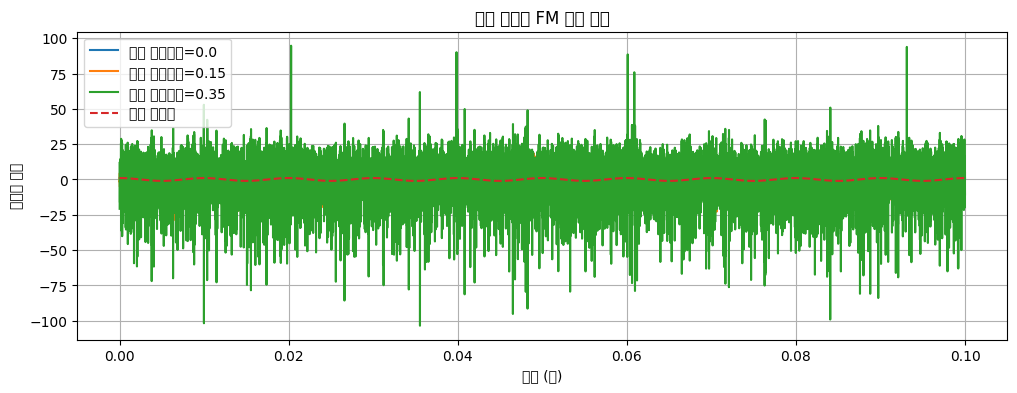

In [8]:
def fm_demod_noise(noise_std):
    fs = 100_000
    tt = np.arange(0, 0.1, 1/fs)
    fm = 100
    fc = 2_000
    delta_f = 500

    msg = np.cos(2*np.pi*fm*tt)
    clean = np.cos(2*np.pi*fc*tt + (delta_f/fm)*np.sin(2*np.pi*fm*tt))

    # noise_std가 클수록 잡음의 흔들림이 커집니다.
    noise = np.random.normal(0, noise_std, size=len(tt))
    noisy = clean + noise

    ph = np.unwrap(np.angle(hilbert(noisy)))
    inst = np.diff(ph) * fs / (2*np.pi)
    out = (inst - fc)
    out = (out - np.mean(out)) / delta_f

    # return은 함수가 계산한 결과를 함수 바깥으로 돌려줍니다.
    return tt, msg, tt[1:], out

plt.figure(figsize=(12, 4))
for noise in [0.0, 0.15, 0.35]:
    # for는 목록 안의 값을 하나씩 꺼내 반복합니다.
    tt, msg, td, out = fm_demod_noise(noise)
    plt.plot(td, out, label=f"잡음 표준편차={noise}")

plt.plot(tt, msg, "--", label="원래 메시지")
plt.title("잡음 수준별 FM 복조 결과")
plt.xlabel("시간 (초)")
plt.ylabel("정규화 진폭")
plt.legend()
plt.grid(True)
plt.show()

## 7. 정리 및 응용 실습

### 꼭 기억할 파이썬 문법
- `이름 = 값`: 값을 변수에 저장
- `라이브러리.함수(...)`: 라이브러리의 기능 호출
- `# 설명`: 실행되지 않는 주석
- `def 함수이름(...):`: 함수 정의
- `for 변수 in 목록:`: 목록의 항목을 하나씩 반복
- `return`: 함수의 결과를 반환
- `변수[조건]`: 조건에 맞는 배열 항목 선택

### 통신 개념 정리
- FM은 진폭보다 순간 주파수 변화에 정보를 실습니다.
- \(β=Δ f/f_m\)은 단일 정현파 FM의 변조지수입니다.
- FFT는 신호의 주파수 성분을 관찰하는 도구입니다.
- 위상 차분으로 순간 주파수를 추정해 복조 원리를 확인할 수 있습니다.

### 직접 해보기
1. `fm`을 200 Hz로 바꾸고 변조지수를 계산하세요.
2. `delta_f`를 100, 500, 1000 Hz로 바꾸어 파형과 스펙트럼을 비교하세요.
3. 잡음 표준편차를 0.05, 0.2, 0.5로 바꾸세요.
4. 바꾼 값과 관찰 결과를 3~5문장으로 정리하세요.